# Data pull: California gasoline forecasting project

Builds `weekly_data.csv` (one row per EIA Monday) and `data_dictionary.csv` — the shared input for every model.

**Sources** (no API keys needed; optional keys used as fallback)
- EIA weekly retail gasoline: California regular (`EMM_EPMR_PTE_SCA_DPG`) — forecast target
- FRED: U.S. regular gasoline (`GASREGW`), Brent (`DCOILBRENTEU`), WTI (`DCOILWTICO`)
- EIA Weekly Petroleum Status Report, West Coast (PADD 5): gross refinery inputs (`WGIRIP52`), total gasoline stocks (`WGTSTP51`)
- Event calendar: compiled below, each row with a source note

**No-look-ahead alignment rules** (for gas price date *t*, a Monday)
- Retail gas (CA, US): EIA surveys Monday morning, so value at *t*.
- Crude (Brent, WTI): average of the **previous** Mon–Fri trading days (*t*−7 … *t*−3). Same-week averaging would use prices after the gas observation.
- PADD 5 inputs/stocks: week-ending Friday, released the following Wednesday. Use the latest week whose release date (week end + 5 days) is ≤ *t*, i.e. the week ending *t*−10.

In [1]:
import os, io, time
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", category=DeprecationWarning)

# ---- settings ----
START = "2000-01-01"
TEST_START = "2025-07-01"       # train: before this date; test: on/after
REFRESH = False                 # True = re-download even if cached raw files exist
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

EIA_API_KEY = os.getenv("EIA_API_KEY")    # optional fallback
FRED_API_KEY = os.getenv("FRED_API_KEY")  # optional fallback
HEADERS = {"User-Agent": "Mozilla/5.0 (UCLA Anderson time-series class project)"}

SERIES = {
    # name: (source, id, description, units)
    "ca_gas":    ("eia",  "EMM_EPMR_PTE_SCA_DPG", "California regular gasoline retail price, all formulations", "USD/gal"),
    "us_gas":    ("fred", "GASREGW",              "U.S. regular gasoline retail price, all formulations",       "USD/gal"),
    "brent":     ("fred", "DCOILBRENTEU",         "Brent crude spot price (Europe), daily",                     "USD/bbl"),
    "wti":       ("fred", "DCOILWTICO",           "WTI crude spot price (Cushing, OK), daily",                  "USD/bbl"),
    "p5_inputs": ("eia",  "WGIRIP52",             "West Coast (PADD 5) refiner gross inputs, weekly",           "thousand bbl/day"),
    "p5_stocks": ("eia",  "WGTSTP51",             "West Coast (PADD 5) total motor gasoline stocks, weekly",    "thousand bbl"),
}

## 1. Download (cached in `data/raw/`)

In [2]:
def _get(url, params=None, tries=3):
    for i in range(tries):
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=60)
            r.raise_for_status()
            return r
        except Exception as e:
            if i == tries - 1:
                raise
            time.sleep(2 * (i + 1))

def fetch_fred(sid):
    # Keyless CSV endpoint; falls back to the FRED API if a key is set.
    try:
        r = _get("https://fred.stlouisfed.org/graph/fredgraph.csv", {"id": sid})
        df = pd.read_csv(io.StringIO(r.text))
        df.columns = ["date", "value"]          # handles DATE or observation_date header
    except Exception:
        if not FRED_API_KEY:
            raise
        r = _get("https://api.stlouisfed.org/fred/series/observations",
                 {"series_id": sid, "api_key": FRED_API_KEY, "file_type": "json"})
        df = pd.DataFrame(r.json()["observations"])[["date", "value"]]
    df["date"] = pd.to_datetime(df["date"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")   # FRED marks holidays with "."
    return df

def fetch_eia(sid):
    # EIA history XLS (keyless); falls back to EIA API v2 if a key is set.
    try:
        r = _get(f"https://www.eia.gov/dnav/pet/hist_xls/{sid}w.xls")
        df = pd.read_excel(io.BytesIO(r.content), sheet_name="Data 1", skiprows=2)
        df = df.iloc[:, :2]
        df.columns = ["date", "value"]
    except Exception:
        if not EIA_API_KEY:
            raise
        r = _get(f"https://api.eia.gov/v2/seriesid/PET.{sid}.W", {"api_key": EIA_API_KEY})
        df = pd.DataFrame(r.json()["response"]["data"])[["period", "value"]]
        df.columns = ["date", "value"]
    df["date"] = pd.to_datetime(df["date"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    return df

def read_local(src, sid):
    # Files saved by a browser download: fred_<ID>.csv / eia_<ID>.xls
    if src == "fred" and (RAW_DIR / f"fred_{sid}.csv").exists():
        df = pd.read_csv(RAW_DIR / f"fred_{sid}.csv")
    elif src == "eia" and (RAW_DIR / f"eia_{sid}.xls").exists():
        df = pd.read_excel(RAW_DIR / f"eia_{sid}.xls", sheet_name="Data 1", skiprows=2).iloc[:, :2]
    else:
        return None
    df.columns = ["date", "value"]
    df["date"] = pd.to_datetime(df["date"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    return df

def load(name):
    src, sid, _, _ = SERIES[name]
    df = None if REFRESH else read_local(src, sid)
    if df is None:
        df = fetch_fred(sid) if src == "fred" else fetch_eia(sid)
        df.to_csv(RAW_DIR / f"{src}_{sid}.csv", index=False) if src == "fred" else df.to_csv(RAW_DIR / f"eia_{sid}.csv", index=False)
    return df.dropna().sort_values("date").reset_index(drop=True)

raw = {name: load(name) for name in SERIES}
pd.DataFrame({n: [d["date"].min().date(), d["date"].max().date(), len(d)] for n, d in raw.items()},
             index=["first", "last", "rows"]).T

,first,last,rows
ca_gas,2000-05-22,2026-10-05,1377
us_gas,1990-08-20,2026-10-05,1880
brent,1987-05-20,2026-10-06,9102
wti,1986-01-02,2026-10-06,9517
p5_inputs,1990-01-05,2026-10-02,1916
p5_stocks,1990-01-05,2026-10-02,1917


## 2. Align everything to the EIA Monday calendar

In [3]:
# Spine: California gas dates (Mondays). EIA occasionally shifts a survey day for holidays,
# so snap every date to its week's Monday before merging.
def to_monday(s):
    return s - pd.to_timedelta(s.dt.weekday, unit="D")

ca = raw["ca_gas"].assign(date=lambda d: to_monday(d["date"]))
ca = ca[ca["date"] >= START].drop_duplicates("date", keep="last")
week = ca.rename(columns={"value": "ca_gas"}).set_index("date")

# U.S. gas: same Monday survey
us = raw["us_gas"].assign(date=lambda d: to_monday(d["date"])).drop_duplicates("date", keep="last")
week = week.join(us.set_index("date")["value"].rename("us_gas"))

# Crude: previous Mon-Fri average (dates t-7 ... t-3)
def prev_week_avg(daily, mondays):
    s = daily.set_index("date")["value"]
    out, n = [], []
    for t in pd.DatetimeIndex(mondays):
        w = s.loc[t - pd.Timedelta(days=7): t - pd.Timedelta(days=3)]
        out.append(w.mean() if len(w) else np.nan)
        n.append(len(w))
    return pd.Series(out, index=mondays), pd.Series(n, index=mondays)

for c in ["brent", "wti"]:
    avg, n = prev_week_avg(raw[c], week.index)
    week[c] = avg
    week[f"{c}_ndays"] = n          # trading days in the average (0 = no data that week)

# PADD 5 weekly data: available at t if (week_end + 5 days) <= t
def asof_release(df, name, mondays, lag_days=5):
    d = df.assign(release=df["date"] + pd.Timedelta(days=lag_days)).sort_values("release")
    m = pd.merge_asof(pd.DataFrame({"t": mondays}), d[["release", "date", "value"]],
                      left_on="t", right_on="release", direction="backward")
    return m.set_index("t")["value"].rename(name), m.set_index("t")["date"].rename(f"{name}_week_end")

for c in ["p5_inputs", "p5_stocks"]:
    v, we = asof_release(raw[c], c, week.index)
    week[c] = v
    week[f"{c}_week_end"] = we

# Fill rules: crude weeks with zero trading days (rare) carry the last value forward and are flagged
for c in ["brent", "wti"]:
    week[f"{c}_filled"] = week[c].isna().astype(int)
    week[c] = week[c].ffill()

week.index.name = "date"
week.tail()

,ca_gas,us_gas,brent,brent_ndays,wti,wti_ndays,p5_inputs,p5_inputs_week_end,p5_stocks,p5_stocks_week_end,brent_filled,wti_filled
date,,,,,,,,,,,,
2026-09-07,5.678,4.157,99.0925,4,91.1800,5,2110,2026-08-28,27203,2026-08-28,0,0
2026-09-14,5.827,4.319,111.8280,5,99.0775,4,2119,2026-09-04,27070,2026-09-04,0,0
2026-09-21,6.003,4.478,124.1460,5,103.5420,5,2159,2026-09-11,27386,2026-09-11,0,0
2026-09-28,6.189,4.465,117.0840,5,93.5740,5,2150,2026-09-18,27328,2026-09-18,0,0
2026-10-05,6.227,4.354,120.0340,5,98.0740,5,2125,2026-09-25,27990,2026-09-25,0,0


## 3. Event calendar

Edit this table, not the code. `kind = pulse` → dummy is 1 between `start` and `end`; `kind = step` → 1 from `start` onward (permanent capacity loss).
Rows marked `verify = True` have dates that need a source check before the final run — replace the `source` note with the actual citation.

In [4]:
EVENTS = pd.DataFrame([
    # name,               kind,   start,        end,          description,                                         source,                                                  verify
    ("richmond_fire_2012","pulse","2012-08-06", "2012-10-29", "Chevron Richmond crude unit fire (Aug 6, 2012)",    "U.S. Chemical Safety Board report",                     False),
    ("torrance_2012",     "pulse","2012-10-01", "2012-10-29", "Oct 2012 supply crunch (Torrance power outage)",    "CEC; news coverage Oct 2012",                           True),
    ("torrance_2015",     "pulse","2015-02-16", "2016-05-30", "ExxonMobil Torrance explosion (Feb 18, 2015), reduced output until mid-2016", "U.S. Chemical Safety Board report", False),
    ("covid",             "pulse","2020-03-16", "2020-06-29", "COVID-19 demand collapse",                          "CA stay-at-home order, Mar 19, 2020",                   False),
    ("fall_2022_outages", "pulse","2022-09-19", "2022-10-31", "Multiple refinery outages; early winter-blend order", "CEC; Governor order Sep 30, 2022",                      False),
    ("martinez_fire_2025","pulse","2025-02-03", "2025-04-28", "PBF Martinez refinery fire (Feb 1, 2025)",          "news coverage Feb 2025",                                True),
    ("iran_war_2026",     "pulse","2026-02-23", "2026-12-31", "Iran war / Strait of Hormuz disruption, crude shock","Wikipedia '2026 Iran war fuel crisis'; CNBC timeline Apr 21, 2026", False),
    ("marathon_martinez", "step", "2020-04-27", None,         "Marathon Martinez idled (renewable conversion)",    "company announcement 2020",                             True),
    ("p66_rodeo",         "step", "2024-02-05", None,         "Phillips 66 Rodeo stops crude processing",          "company announcement (Rodeo Renewed), early 2024",      True),
    ("p66_los_angeles",   "step", "2025-10-06", None,         "Phillips 66 Los Angeles phased closure (Q4 2025)",  "Phillips 66 8-K Oct 16, 2024; Nasdaq/Zacks on phased closure", False),
    ("valero_benicia",    "step", "2026-04-27", None,         "Valero Benicia ends fuel production (~Apr 30, 2026)","Argus Media Apr 30, 2026",                             False),
], columns=["name", "kind", "start", "end", "description", "source", "verify"])

# Recurring calendar effects (rules, not one-off dates)
def summer_blend(d):      # CARB summer RVP season at retail, approx. Apr 1 - Oct 31 (southern CA); verify regional dates
    return ((d.month >= 4) & (d.month <= 10)).astype(int)

def july_tax(d):          # first 4 weeks after the annual July 1 excise change (annual adjustments since 2010)
    jul1 = pd.to_datetime(d.year.astype(str) + "-07-01")
    return (((d - jul1).days >= 0) & ((d - jul1).days < 28) & (d.year >= 2010)).astype(int)

idx = week.index
week["ev_summer_blend"] = summer_blend(idx)
week["ev_july_tax"] = july_tax(idx)
for _, e in EVENTS.iterrows():
    s = pd.Timestamp(e["start"])
    if e["kind"] == "step":
        week[f"ev_{e['name']}"] = (idx >= s).astype(int)
    else:
        week[f"ev_{e['name']}"] = ((idx >= s) & (idx <= pd.Timestamp(e["end"]))).astype(int)

week["closures_cum"] = week[[f"ev_{n}" for n in EVENTS.loc[EVENTS.kind == "step", "name"]]].sum(axis=1)
EVENTS.to_csv(DATA_DIR / "events.csv", index=False)
print("Rows still needing a source check:", EVENTS["verify"].sum())

Rows still needing a source check: 4


## 4. Transforms and train/test split

In [5]:
def safe_log(x):
    return np.log(x.where(x > 0))     # WTI went negative on 2020-04-20; logs undefined there

week["ca_us_spread"] = week["ca_gas"] - week["us_gas"]
week["brent_gal"] = week["brent"] / 42           # crude in USD/gal, comparable to pump prices
for c in ["ca_gas", "us_gas", "brent", "wti"]:
    week[f"log_{c}"] = safe_log(week[c])
    week[f"dlog_{c}"] = week[f"log_{c}"].diff()
week["d_ca_gas"] = week["ca_gas"].diff()
week["split"] = np.where(week.index < TEST_START, "train", "test")

# column order
base = ["ca_gas", "us_gas", "ca_us_spread", "brent", "wti", "brent_gal", "p5_inputs", "p5_stocks"]
trans = [c for c in week.columns if c.startswith(("log_", "dlog_", "d_"))]
evs = [c for c in week.columns if c.startswith("ev_")] + ["closures_cum"]
meta = ["brent_ndays", "wti_ndays", "brent_filled", "wti_filled", "p5_inputs_week_end", "p5_stocks_week_end", "split"]
week = week[base + trans + evs + meta]
week.groupby("split").size()

split
test       66
train    1311
dtype: int64

## 5. Checks

In [6]:
checks = {
    "all dates are Mondays": bool((week.index.weekday == 0).all()),
    "no duplicate weeks": bool(week.index.is_unique),
    "gaps > 7 days in spine": int((week.index.to_series().diff().dt.days > 7).sum()),
    "missing ca_gas": int(week["ca_gas"].isna().sum()),
    "missing us_gas": int(week["us_gas"].isna().sum()),
    "brent weeks forward-filled": int(week["brent_filled"].sum()),
    "latest week: Brent trading days in avg (FRED lags ~1 wk; <3 = partial)": int(week["brent_ndays"].iloc[-1]),
    "PADD5 data older than 10 days (max lag, days)": int((week.index - week["p5_stocks_week_end"]).dt.days.max()),
    "first week": str(week.index.min().date()),
    "last week": str(week.index.max().date()),
    "test weeks": int((week["split"] == "test").sum()),
}
pd.Series(checks)

all dates are Mondays                                                           True
no duplicate weeks                                                              True
gaps > 7 days in spine                                                             0
missing ca_gas                                                                     0
missing us_gas                                                                     0
brent weeks forward-filled                                                         1
latest week: Brent trading days in avg (FRED lags ~1 wk; <3 = partial)             5
PADD5 data older than 10 days (max lag, days)                                     17
first week                                                                2000-05-22
last week                                                                 2026-10-05
test weeks                                                                        66
dtype: object

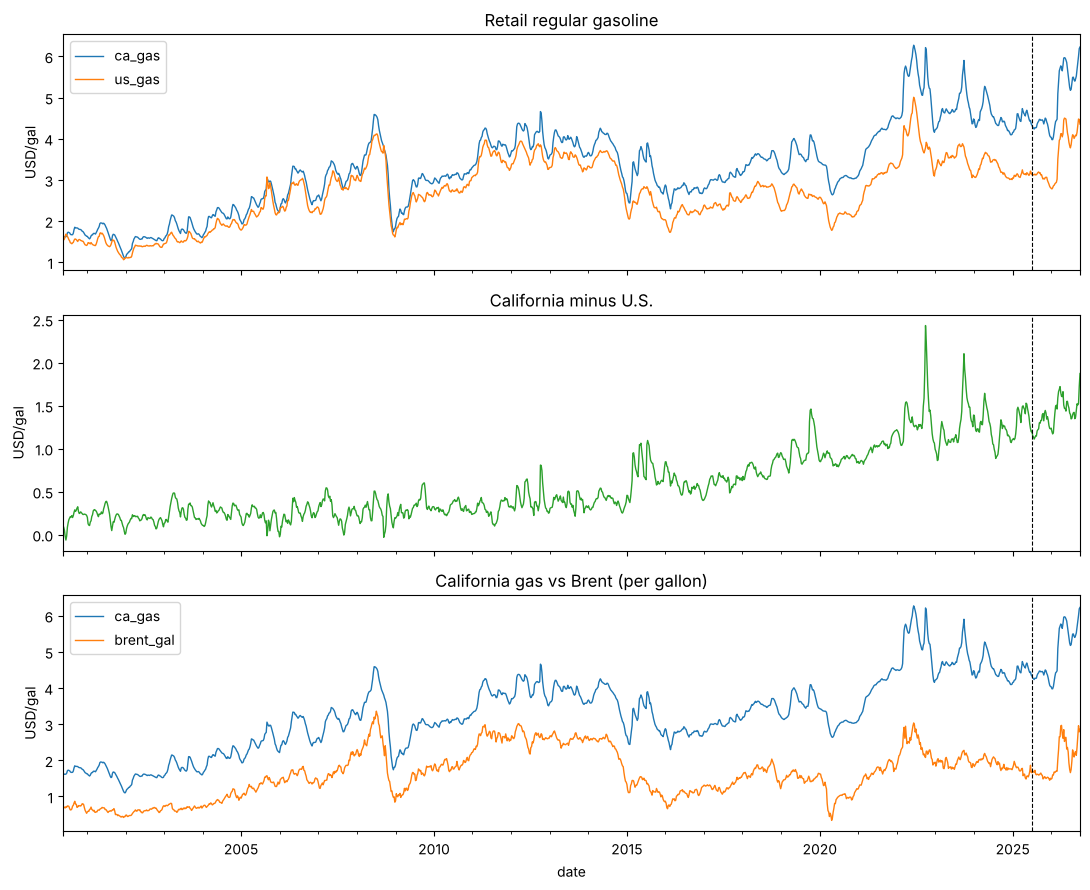

In [7]:
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
week[["ca_gas", "us_gas"]].plot(ax=ax[0], lw=1); ax[0].set_ylabel("USD/gal"); ax[0].set_title("Retail regular gasoline")
week["ca_us_spread"].plot(ax=ax[1], lw=1, color="C2"); ax[1].set_ylabel("USD/gal"); ax[1].set_title("California minus U.S.")
week[["ca_gas", "brent_gal"]].plot(ax=ax[2], lw=1); ax[2].set_ylabel("USD/gal"); ax[2].set_title("California gas vs Brent (per gallon)")
for a in ax:
    a.axvline(pd.Timestamp(TEST_START), color="k", ls="--", lw=0.8)
plt.tight_layout(); plt.show()

## 6. Write shared files

In [8]:
DICT = [
    ("date", "EIA survey Monday (week index)", "date", "EIA"),
    ("ca_gas", SERIES["ca_gas"][2], "USD/gal", "EIA EMM_EPMR_PTE_SCA_DPG"),
    ("us_gas", SERIES["us_gas"][2], "USD/gal", "FRED GASREGW"),
    ("ca_us_spread", "ca_gas - us_gas", "USD/gal", "derived"),
    ("brent", "Brent spot, mean of previous Mon-Fri", "USD/bbl", "FRED DCOILBRENTEU"),
    ("wti", "WTI spot, mean of previous Mon-Fri (robustness only)", "USD/bbl", "FRED DCOILWTICO"),
    ("brent_gal", "brent / 42", "USD/gal", "derived"),
    ("p5_inputs", "PADD 5 refiner gross inputs, latest week released by t", "thousand bbl/day", "EIA WGIRIP52"),
    ("p5_stocks", "PADD 5 total gasoline stocks, latest week released by t", "thousand bbl", "EIA WGTSTP51"),
    ("log_*", "natural log of the series (NaN if <= 0)", "log", "derived"),
    ("dlog_*", "weekly change in log (approx. % change)", "log diff", "derived"),
    ("d_ca_gas", "weekly change in ca_gas", "USD/gal", "derived"),
    ("ev_summer_blend", "1 in Apr-Oct (CARB summer gasoline season)", "0/1", "rule"),
    ("ev_july_tax", "1 in the 4 weeks after July 1 excise adjustment, 2010+", "0/1", "rule"),
    ("ev_<event>", "event dummies; definitions and sources in events.csv", "0/1", "events.csv"),
    ("closures_cum", "number of permanent CA refinery closures to date", "count", "events.csv"),
    ("*_ndays", "trading days in the crude weekly average", "count", "derived"),
    ("*_filled", "1 if crude value carried forward (no trading days that week)", "0/1", "derived"),
    ("*_week_end", "week-ending Friday of the PADD 5 value used", "date", "EIA WPSR"),
    ("split", f"train if date < {TEST_START}, else test", "label", "derived"),
]
pd.DataFrame(DICT, columns=["column", "definition", "units", "source"]).to_csv(DATA_DIR / "data_dictionary.csv", index=False)

week.reset_index().to_csv(DATA_DIR / "weekly_data.csv", index=False, date_format="%Y-%m-%d")
print("Wrote", DATA_DIR / "weekly_data.csv", week.shape)

Wrote /home/claude/gasproj/data/weekly_data.csv (1377, 38)


## Forecast output format (agreed for all models)

Every model writes `forecasts/<model>.csv` with exactly these columns, so Member 3 can score and Member 6 can display any model:

| column | meaning |
|---|---|
| model | e.g. `naive`, `ets`, `arima_fourier`, `arimax`, `chronos`, `timesfm`, `llm_claude_anon` |
| origin_date | last Monday of data the model saw |
| horizon | weeks ahead, 1–12 |
| target_date | origin_date + 7 × horizon days |
| forecast | point forecast, USD/gal |
| lower80, upper80 | 80% interval, USD/gal (blank if the model has none) |